# [Bonus Tasks](svm_segm.ipynb)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import scipy.ndimage as ndi
import skimage.morphology as morph
import skimage.util
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

In [2]:
def blend_result(img, seg, border_radius=1, interior_opacity=1, interior_opacity_decay=0.9, color=(0,1,0)):
    img  = np.dstack([img] * 3).copy()
    img -= img.min()
    img /= img.max()
    selem  = morph.disk(border_radius)
    seg_bd = np.logical_xor(morph.binary_dilation(seg, selem), morph.binary_erosion(seg, selem))
    mask_decay = ndi.distance_transform_edt(seg)
    for i in range(3):
        opacity = interior_opacity / pow(1 + mask_decay[seg], interior_opacity_decay)
        img[:,:,i][seg] = color[i] * opacity + (1 - opacity) * img[:,:,i][seg]
        img[:,:,i][seg_bd] = color[i]
    return img

In [3]:
patch_sizes = (32, 32)

---

**[Task 1.1.]()** Implement `create_data_matrix`:

In [4]:
def create_data_matrix(img):
    patches = skimage.util.view_as_blocks(img, block_shape=patch_sizes)

    X = patches.reshape(-1, patch_sizes[0] * patch_sizes[1])

    return X

**[Task 1.2.]()** Implement `create_gt_labels_vector`:

In [5]:
def create_gt_labels_vector(gt_img):
    patches = create_data_matrix(gt_img)

    foreground_fraction = np.mean(patches > 0, axis=1)

    y = np.where(foreground_fraction > 0.5, 1,
                 np.where(foreground_fraction == 0, -1, 0))

    return y

**[Task 1.3.]()** Create the SVM classifier:

In [6]:
clf = make_pipeline(StandardScaler(), SVC(class_weight='balanced', gamma=0.1))

**[Task 1.3 (a).]()** Create the data matrices for the images `dna-33` and `dna-44`:

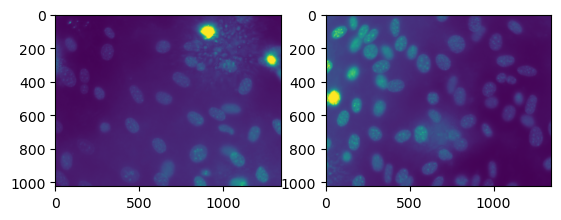

In [ ]:
img1 = plt.imread('data/NIH3T3/im/dna-33.png')
img2 = plt.imread('data/NIH3T3/im/dna-44.png')

plt.figure()
plt.subplot(1,2,1)
plt.imshow(img1)
plt.subplot(1,2,2)
plt.imshow(img2)
plt.show()



In [15]:
A1 = create_data_matrix(img1)
A2 = create_data_matrix(img2)

**[Task 1.3 (b).]()** Create the corresponding ground truth label vectors:

In [16]:
y1 = create_gt_labels_vector(img1)
y2 = create_gt_labels_vector(img2)

**[Task 1.3 (c).]()** Create the *combined* data matrices and ground truth label vectors:

**[Task 1.3 (d).]()** Train the classifier using the data matrix and label vectors from above:

**[Task 1.4.]()** Implement the function `predict_image`:

Test your implementation:

In [ ]:
img = plt.imread(f'data/NIH3T3/im/dna-0.png')
seg = predict_image(img)

plt.figure()
plt.imshow(blend_result(img, seg))

**[Task 1.5.]()** Perform batch processing: